In [1]:
import os
os.environ['CUDA_VISIBLE_DEVICES'] = "1"
import scanpy as sc
import seaborn as sns
from tqdm import tqdm
import numpy as np
import pandas as pd
from collections import Counter,defaultdict

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.amp import autocast, GradScaler

from Henosis.dataprocess.h5a import H5ADTokenizer
from Henosis.const import set_species_context
from Henosis import data
import Henosis.resa as resa
import Henosis.utils as utils
import Henosis.mmd as mmd
import Henosis.lr_schedule as lr_sche
import Henosis.henosis as henosis

In [2]:
organ='agebrain'
species_to_adata = {
    "homo_sapiens": sc.read_h5ad(f"/mnt/public8/caoguangshuo/Orthoformer/Figure3/pdata/pdata2/h5data/{organ}/homo_sapiens.h5ad"),
    "Mus_musculus": sc.read_h5ad(f"/mnt/public8/caoguangshuo/Orthoformer/Figure3/pdata/pdata2/h5data/{organ}/Mus_musculus.h5ad"),
}

In [3]:
species_to_embed_file = {
    "homo_sapiens": f"/mnt/public8/caoguangshuo/Orthoformer/Figure3/pdata/pdata2/esm_embedding/{organ}/homo_sapiens.avg.embeddings",
    "Mus_musculus": f"/mnt/public8/caoguangshuo/Orthoformer/Figure3/pdata/pdata2/esm_embedding/{organ}/Mus_musculus.avg.embeddings",
}

In [4]:
species_dict=set_species_context(species_to_adata)
token_species_dict={v:k for k,v in species_dict.items()}

In [5]:
tokenized = H5ADTokenizer(
    species_to_adata,
    species_to_embed_file,
).process_species_adata()

100%|██████████| 157480/157480 [00:02<00:00, 61625.90it/s]


In [6]:
species_to_reps = {
    "homo_sapiens": "X_pca",
    "Mus_musculus": "X_pca",
}

In [7]:
train_loader, test_loader = data.prepare_multispecies_dataloaders(
    tokenized,
    batch_size=512,
    species_to_reps=species_to_reps,
    batch_species=len(species_to_adata),
)

homo_sapiens: X_pca
Mus_musculus: X_pca


In [8]:
d_model=120
embed_size=480
scale=4
input_size=50
latent_size=64
num_layers=1
n_clusters=100000
net=henosis.Henosis(species_to_embed_file,d_model,embed_size,latent_size,encoder_type='mean_pool')

PCA ing
PCA done


In [9]:
def train_epoch(net,train_loader,loss_fn,loss_fn1,optimizer,scaler,device,current_temp,scheduler,ml_weight=1.0):
    net.train()
    metrics=utils.Accumulator(4)
    pbar=tqdm(train_loader,desc='Processing')
    for _,batch in enumerate(pbar):
        optimizer.zero_grad(set_to_none=True)

        data,adata,sp=batch
        data = data.to(device, non_blocking=True)
        adata = adata.float().to(device, non_blocking=True)
        sp = sp.to(device, non_blocking=True)

        with autocast('cuda'):
            sl = torch.tensor(0.0, device=device)
            protein_features,gene_features,logit_scales=net(adata,data,sp,)
            species_ids = torch.unique(sp).tolist()
            #for i in torch.unique(sp):
            for s in species_ids:
                mask = (sp == s)

                indices = torch.nonzero(mask).squeeze(1)
                protein_features_i = torch.index_select(protein_features, 0, indices)
                gene_features_i = torch.index_select(gene_features, 0, indices)
                sl += loss_fn(protein_features_i, gene_features_i, logit_scales[int(s)],)
            ml=loss_fn1(protein_features,sp)
            loss=sl+ml*ml_weight

        scaler.scale(loss).backward()
        if net.transformer.embed.gene_embed.weight.grad is not None:
            #net.transformer.embed.gene_embed.weight.grad[3:-1] = 0
            net.transformer.embed.gene_embed.weight.grad[4:] = 0
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(net.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()

        if scheduler:
            scheduler.step()
        lr=optimizer.param_groups[0]['lr']
        pbar.set_description(f"loss:{loss.detach().item():.4f},sl:{sl.detach().item():.8f},ml:{ml.detach().item():.8f},lr:{lr:.8f}")
        metrics.add(loss.detach().item() * len(sp), sl.detach().item() * len(sp),ml.detach().item() * len(sp), len(sp))

    return {'loss':metrics[0] / metrics[3],'sl':metrics[1] / metrics[3],'ml':metrics[2] / metrics[3],}

def train(net,train_loader,test_loader,epochs,lr,species_to_h5,net_path,temp,ml_weight):
    def init_weights(m):
        if type(m) == nn.Linear or type(m) == nn.Conv1d:
            nn.init.xavier_uniform_(m.weight)
    net.apply(init_weights)
    print('init done')

    device =torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print('training on', device)
    net.to(device)

    loss_fn=resa.MultiScaleReSALoss()#swav.ATACKNNLoss()#
    loss_fn1=mmd.MMMD(kernel_type='rbf',each=True)#mmd.MSampleLoss(each=True)#
    optimizer = torch.optim.AdamW(net.parameters(), lr=lr,fused=True)
    scheduler = lr_sche.CosineAnnealingWarmupRestarts(
        optimizer,
        first_cycle_steps=2000,   # 一个周期 2000 batch
        cycle_mult=1,             # 不增加周期长度
        max_lr=lr*1.5,            # 最大 lr 稍高
        min_lr=1e-6,
        warmup_steps=400,         # 前 400 batch 线性升到 max_lr
        gamma=0.6
    )
    early_stopping = utils.EarlyStopping(
        patience=10,               # 连续5个epoch指标不提升就停止
        verbose=True, 
        path=net_path, # 保存的文件名
        mode='min'                # 如果监控的是准确率，这里改用 'max'
    )
    scaler = GradScaler('cuda')
    cr_ml_weight=0.0
    warm_epoch=5
    try:
        for epoch in range(epochs):
            print(f"epoch:{epoch},")
            print(f"Temp: {temp}")
            if epoch>=warm_epoch:
                cr_ml_weight=ml_weight
            losses=train_epoch(net,train_loader,loss_fn,loss_fn1,optimizer,scaler,device,temp,scheduler,cr_ml_weight)
            current_lr = optimizer.param_groups[0]['lr']
            print(f"lr:{current_lr},")
            print(f'{losses}')
            if epoch>=warm_epoch:
                early_stopping(losses['loss'],net)
                if early_stopping.early_stop:
                    print("====== Early stopping triggered! ======")
                    #infer_latent(net,test_loader,device,fcell_path,fsp_path,species_to_h5)
                    break
            if epoch ==epochs-1:
                torch.save(net.state_dict(), net_path)
                print(f'saving weight in {net_path}')
                #infer_latent(net,test_loader,device,fcell_path,fsp_path,species_to_h5)
                break
    except KeyboardInterrupt:
        #infer_latent(net,test_loader,device,fcell_path,fsp_path,species_to_h5)
        torch.save(net.state_dict(), net_path)
        print(f'saving weight in {net_path}')

In [10]:
net_path=f'/mnt/public5/panguanyu/cross_species/gefor/code/pth/ReSA_{organ}.pth'
species_to_h5=tokenized
epochs=100
lr=1e-3
train(net,train_loader,test_loader,epochs,lr,species_to_h5,net_path,temp=0.2,ml_weight=0.0)

init done
training on cuda
epoch:0,
Temp: 0.2


loss:8.4373,sl:8.43730736,ml:0.09413838,lr:0.00147344: 100%|██████████| 536/536 [00:15<00:00, 34.87it/s] 


lr:0.0014734357851341198,
{'loss': 9.111402086357572, 'sl': 9.111402086357572, 'ml': 0.3633877717292131}
epoch:1,
Temp: 0.2


loss:7.9286,sl:7.92864609,ml:0.06118441,lr:0.00093689: 100%|██████████| 536/536 [00:15<00:00, 34.72it/s]


lr:0.0009368930704300587,
{'loss': 8.102637061432226, 'sl': 8.102637061432226, 'ml': 0.06533097331203631}
epoch:2,
Temp: 0.2


...

lr:1.8186465585354374e-06,
{'loss': 7.620724488550158, 'sl': 7.620724488550158, 'ml': 0.053581462644819}
EarlyStopping counter: 8 out of 10
epoch:50,
Temp: 0.2


loss:7.6240,sl:7.62398767,ml:0.05367100,lr:0.00000135: 100%|██████████| 536/536 [00:17<00:00, 31.13it/s]


lr:1.3530111888327049e-06,
{'loss': 7.620995272451372, 'sl': 7.620995272451372, 'ml': 0.05364363206856286}
EarlyStopping counter: 9 out of 10
epoch:51,
Temp: 0.2


loss:7.6280,sl:7.62799597,ml:0.05405152,lr:0.00000102: 100%|██████████| 536/536 [00:17<00:00, 30.86it/s]

lr:1.015066009522985e-06,
{'loss': 7.6212496526205715, 'sl': 7.6212496526205715, 'ml': 0.05376443133425357}
EarlyStopping counter: 10 out of 10
====== Early stopping triggered! ======


infering: 100%|██████████| 358/358 [00:04<00:00, 73.58it/s]


computing PCA
    with n_comps=25
    finished (0:00:01)
Running MOT_Correction by 'inferred_species' -> adata.obsm['X_mot']
X_mot shape: (183151, 25)
computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:16)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:02:25)


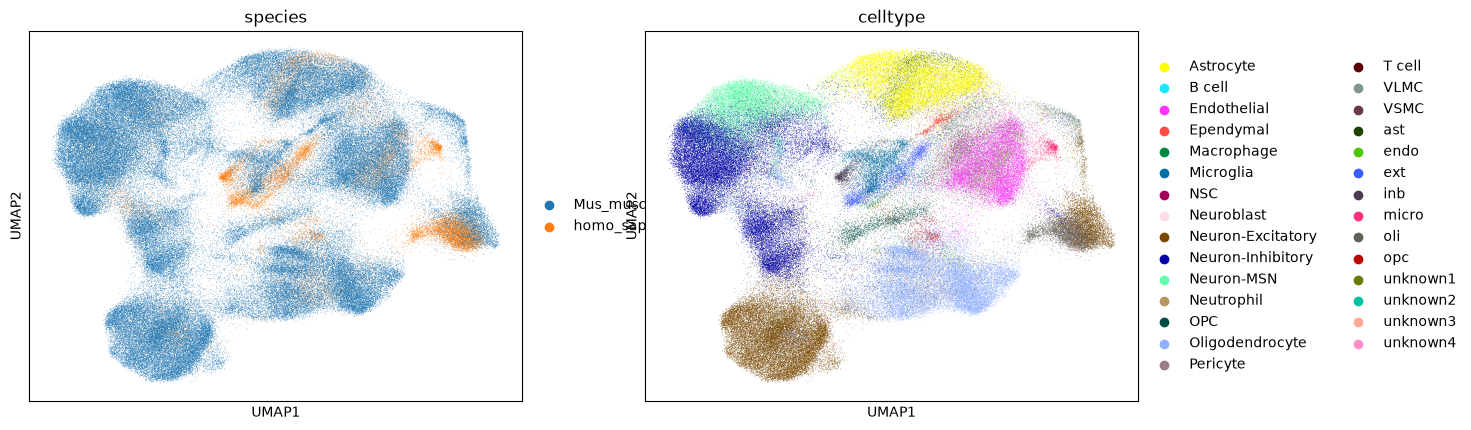

In [13]:
import importlib
import Henosis.evaluate
importlib.reload(Henosis.evaluate)
from Henosis.evaluate import evaluate_integration

integrated_adata = evaluate_integration(
    net,
    test_loader,
    species_to_adata=tokenized,
    #metadata_columns=["cluster"],
    # 如果不同物种列名不一样，改用：
     species_to_metadata_columns={
        "one":["celltype",],
        "homo_sapiens": ["celltype",],
        "Mus_musculus": ["celltype", ],
     },
    embedding="protein",
    use_mot_correction=True,
    correction_by="inferred_species",
    correction_kwargs={
        "max_rounds": 10,
        "n_clusters": 10,
        "assignment_mode": "sinkhorn",
    },
    umap_colors=["species", "celltype"],
    comatrix_path=f'/mnt/public5/panguanyu/cross_species/gefor/code/comatrix/{organ}.npz',
)